# Evaluación del modelo v2

Este notebook evalúa el modelo elegido en `04_modelado/modelado_v2.ipynb`. La configuración llega fija y aquí no se toma ninguna decisión de modelado; solo se mide.

1. Verificación complementaria sobre desarrollo con GroupKFold por vendedora y StratifiedKFold sin grupos.
2. Test OOT, evaluado una sola vez con el modelo entrenado sobre desarrollo.

## 1. Importaciones

In [1]:
import json
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import GroupKFold, StratifiedKFold
from xgboost import XGBClassifier

## 2. Configuración del modelo v2

`ultima_corrida.json` indica el experimento de la última corrida de modelado. Leemos su `modelo_final.json` desde la carpeta local del experimento, porque las rutas absolutas guardadas pueden ser de otra máquina.

In [2]:
carpeta_modelado = Path("../04_modelado/resultados_v2")
ultima_corrida = json.loads((carpeta_modelado / "ultima_corrida.json").read_text(encoding="utf-8"))
carpeta_experimento = carpeta_modelado / ultima_corrida["experimento"]
especificacion = json.loads((carpeta_experimento / "modelo_final.json").read_text(encoding="utf-8"))

assert especificacion["formato"] == "modelado_v2_individual"
protocolo = especificacion["protocolo"]
configuracion = especificacion["final"]

display(pd.Series({
    "experimento": especificacion["experimento"],
    "modelo": configuracion["nombre"],
    "estrategia": configuracion["estrategia"],
    "ventana_meses": configuracion["ventana_meses"],
    "numero_variables": configuracion["numero_variables"],
    "auc_validacion": round(configuracion["auc_promedio"], 4),
    "lift_validacion": round(configuracion["lift_promedio"], 4),
}, name="valor").to_frame())
print("Variables:", ", ".join(configuracion["variables"]))

,valor
experimento,b2ad959cb4c424b4
modelo,xgboost__seleccionadas
estrategia,sin_tratamiento
ventana_meses,48
numero_variables,6
auc_validacion,0.793
lift_validacion,2.3025


Variables: compras_hist, n_prod_u12, monto_cv_u12, n_ped_u12, monto_u12, ticket_prom_u3


## 3. Datos, desarrollo y OOT

Repetimos el corte de la fase 04 con los parámetros guardados en el protocolo: OOT = últimos 4 meses, brecha de 6 meses, y desarrollo hasta el mes anterior a la brecha.

Exigimos las mismas columnas, el mismo último mes de desarrollo y los mismos tamaños de validación por bloque. Del OOT solo mostramos fechas y tamaño.

In [3]:
datos = pd.read_csv("../data/churn_dataset_processed.csv", parse_dates=["mes_obs"])
assert datos.columns.tolist() == protocolo["columnas"], "Las columnas no coinciden con el modelado."

ultimo_mes_observado = int(datos["mes_rank"].max())
inicio_oot = ultimo_mes_observado - protocolo["meses_oot"] + 1
ultimo_mes_desarrollo = inicio_oot - protocolo["brecha_meses"] - 1
assert ultimo_mes_desarrollo == protocolo["ultimo_mes_desarrollo"]

datos_desarrollo = datos.loc[datos["mes_rank"] <= ultimo_mes_desarrollo].reset_index(drop=True)
datos_oot = datos.loc[datos["mes_rank"] >= inicio_oot].reset_index(drop=True)

mes_texto = datos_desarrollo["mes_obs"].dt.strftime("%Y-%m")
for bloque in protocolo["bloques"]:
    filas = mes_texto.between(bloque["validacion_desde"], bloque["validacion_hasta"]).sum()
    assert filas == bloque["filas_validacion"], f"Bloque {bloque['bloque']}: validación distinta."

display(pd.DataFrame([
    {"conjunto": nombre, "filas": len(tabla),
     "desde": f"{tabla['mes_obs'].min():%Y-%m}", "hasta": f"{tabla['mes_obs'].max():%Y-%m}"}
    for nombre, tabla in [("desarrollo", datos_desarrollo), ("oot", datos_oot)]
]))

,conjunto,filas,desde,hasta
0,desarrollo,29183,2016-12,2025-05
1,oot,879,2025-12,2026-03


## 4. Entrenamiento sobre desarrollo

Entrenamos la configuración fijada en la fase 04 con todo el desarrollo, recortado a su ventana (los últimos 48 meses hasta may-2025). Los hiperparámetros, la semilla y el número de hilos son los guardados.

La fase 04 se corrió en otra máquina con otras versiones de librerías; el modelo se reentrena aquí con la misma configuración. Esto puede mover las predicciones en milésimas, muy por debajo de la incertidumbre del OOT. Las versiones usadas quedan en el reporte.

In [4]:
# ponytail: solo XGBoost sin tratamiento, que es el ganador; otra configuración requiere el pipeline de modelado_v2
assert configuracion["algoritmo"] == "xgboost" and configuracion["estrategia"] == "sin_tratamiento"

entrenamiento = datos_desarrollo
if configuracion["ventana_meses"] is not None:
    entrenamiento = entrenamiento.loc[
        entrenamiento["mes_rank"] > ultimo_mes_desarrollo - configuracion["ventana_meses"]
    ]

variables = configuracion["variables"]
modelo = XGBClassifier(
    tree_method="hist", scale_pos_weight=1.0, n_jobs=protocolo["numero_hilos"],
    random_state=protocolo["semilla"], verbosity=0, **configuracion["parametros"]
)
modelo.fit(entrenamiento[variables], entrenamiento["churn"])

versiones = {nombre: version(nombre) for nombre in ["numpy", "pandas", "scikit-learn", "xgboost"]}
display(pd.Series({
    "filas": len(entrenamiento),
    "desde": f"{entrenamiento['mes_obs'].min():%Y-%m}",
    "hasta": f"{entrenamiento['mes_obs'].max():%Y-%m}",
    "tasa_churn": round(entrenamiento["churn"].mean(), 4),
    "xgboost_aqui": versiones["xgboost"],
    "xgboost_modelado": protocolo["versiones_librerias"]["xgboost"],
}, name="valor").to_frame())

,valor
filas,12240
desde,2021-06
hasta,2025-05
tasa_churn,0.2894
xgboost_aqui,3.2.0
xgboost_modelado,3.4.1


## 5. Verificación con GroupKFold

En la validación temporal una misma vendedora aparece en entrenamiento y en validación, en meses distintos. Esta verificación mide cuánto del desempeño depende de reconocer a la vendedora:

- **GroupKFold(5) por `id_vendedor`:** cada vendedora queda en un solo fold; se valida siempre sobre vendedoras no vistas.
- **StratifiedKFold(5) sin grupos:** mismo esquema, pero la misma vendedora puede quedar en ambos lados. Es el control.

Lo que se interpreta es la diferencia entre ambos: si es cercana a cero, el modelo no depende de memorizar vendedoras. El nivel absoluto no es comparable con la validación temporal, porque los folds aleatorios mezclan épocas y entrenan con meses futuros.

Usamos el mismo pool que el modelo final (ventana de 48 meses) y la misma configuración. El lift es el mismo cálculo de la fase 04: 10 % de mayor riesgo dentro de cada mes.

In [5]:
def calcular_lift_mensual(datos_validacion, probabilidades, proporcion=0.10):
    resultados = datos_validacion[["mes_obs", "churn"]].copy()
    resultados["probabilidad"] = np.asarray(probabilidades, dtype=float)
    lifts = []
    for _, datos_mes in resultados.groupby("mes_obs"):
        numero_contactos = max(1, int(len(datos_mes) * proporcion))
        seleccionadas = datos_mes.nlargest(numero_contactos, "probabilidad")
        lifts.append(seleccionadas["churn"].mean() / datos_mes["churn"].mean())
    return float(np.mean(lifts))


def validacion_cruzada(particionador, grupos=None):
    probabilidades = np.full(len(entrenamiento), np.nan)
    auc_por_fold = []
    for indices_entrenamiento, indices_validacion in particionador.split(
        entrenamiento, entrenamiento["churn"], groups=grupos
    ):
        filas_entrenamiento = entrenamiento.iloc[indices_entrenamiento]
        filas_validacion = entrenamiento.iloc[indices_validacion]
        modelo_fold = clone(modelo).fit(filas_entrenamiento[variables], filas_entrenamiento["churn"])
        probabilidades[indices_validacion] = modelo_fold.predict_proba(filas_validacion[variables])[:, 1]
        auc_por_fold.append(roc_auc_score(filas_validacion["churn"], probabilidades[indices_validacion]))
    assert np.isfinite(probabilidades).all()
    return {
        "auc_promedio": float(np.mean(auc_por_fold)),
        "desviacion_auc": float(np.std(auc_por_fold)),
        "lift_promedio": calcular_lift_mensual(entrenamiento, probabilidades),
        "auc_por_fold": [round(valor, 4) for valor in auc_por_fold],
    }


entrenamiento = entrenamiento.reset_index(drop=True)
verificacion = {
    "group_kfold": validacion_cruzada(GroupKFold(n_splits=5), grupos=entrenamiento["id_vendedor"]),
    "stratified_kfold": validacion_cruzada(
        StratifiedKFold(n_splits=5, shuffle=True, random_state=protocolo["semilla"])
    ),
}
tabla_verificacion = pd.DataFrame([
    {"validacion": "temporal_4_bloques (fase 04)", "auc_promedio": configuracion["auc_promedio"],
     "desviacion_auc": configuracion["desviacion_auc"], "lift_promedio": configuracion["lift_promedio"]},
    *({"validacion": nombre, **{k: v for k, v in resultado.items() if k != "auc_por_fold"}}
      for nombre, resultado in verificacion.items()),
])
display(tabla_verificacion.round(4))
diferencia = verificacion["group_kfold"]["auc_promedio"] - verificacion["stratified_kfold"]["auc_promedio"]
print(f"GroupKFold − StratifiedKFold: {diferencia:+.4f} de AUC")
print("AUC por fold:", {nombre: resultado["auc_por_fold"] for nombre, resultado in verificacion.items()})

,validacion,auc_promedio,desviacion_auc,lift_promedio
0,temporal_4_bloques (fase 04),0.7930,0.0098,2.3025
1,group_kfold,0.7785,0.0083,2.2361
2,stratified_kfold,0.7808,0.0113,2.2283


GroupKFold − StratifiedKFold: -0.0023 de AUC
AUC por fold: {'group_kfold': [0.7856, 0.7632, 0.7767, 0.7853, 0.7817], 'stratified_kfold': [0.7857, 0.7963, 0.7709, 0.765, 0.786]}


## 6. Test OOT (una sola evaluación)

El modelo de la sección 4, entrenado con 2021-06 → 2025-05, predice los cuatro meses del OOT (dic-2025 → mar-2026). Es la única vez que el modelo v2 ve estas filas; los resultados no se usan para ninguna decisión.

Reportamos:

- **AUC-ROC y PR-AUC**, con intervalo de confianza del 95 % por bootstrap. Se remuestrean vendedoras, no filas, porque una misma vendedora aparece hasta cuatro veces en el OOT.
- **AUC y lift del 10 % de mayor riesgo por mes**, con el mismo cálculo que la validación.
- **Precisión, recall y lift según el porcentaje contactado**, ordenando todo el OOT por probabilidad.
- **Matriz de confusión** con el corte 0,5 y con el corte del decil superior.

In [6]:
objetivo_oot = datos_oot["churn"].to_numpy()
probabilidades_oot = modelo.predict_proba(datos_oot[variables])[:, 1]
prevalencia = objetivo_oot.mean()

auc_oot = roc_auc_score(objetivo_oot, probabilidades_oot)
pr_auc_oot = average_precision_score(objetivo_oot, probabilidades_oot)
lift_oot = calcular_lift_mensual(datos_oot, probabilidades_oot)

generador = np.random.default_rng(protocolo["semilla"])
filas_por_vendedora = list(datos_oot.groupby("id_vendedor").indices.values())
muestras_auc, muestras_pr_auc = [], []
for _ in range(2000):
    elegidas = generador.integers(len(filas_por_vendedora), size=len(filas_por_vendedora))
    indices = np.concatenate([filas_por_vendedora[i] for i in elegidas])
    muestras_auc.append(roc_auc_score(objetivo_oot[indices], probabilidades_oot[indices]))
    muestras_pr_auc.append(average_precision_score(objetivo_oot[indices], probabilidades_oot[indices]))

tabla_oot = pd.DataFrame([
    {"metrica": "AUC-ROC", "valor": auc_oot,
     "ic95_inferior": np.percentile(muestras_auc, 2.5), "ic95_superior": np.percentile(muestras_auc, 97.5)},
    {"metrica": "PR-AUC", "valor": pr_auc_oot,
     "ic95_inferior": np.percentile(muestras_pr_auc, 2.5), "ic95_superior": np.percentile(muestras_pr_auc, 97.5)},
    {"metrica": "Lift 10 % mensual", "valor": lift_oot, "ic95_inferior": np.nan, "ic95_superior": np.nan},
])
print(f"OOT: {len(datos_oot)} filas, {len(filas_por_vendedora)} vendedoras, prevalencia {prevalencia:.3f}")
display(tabla_oot.round(4))

tabla_meses = pd.DataFrame([
    {"mes": f"{mes:%Y-%m}", "filas": len(grupo), "tasa_churn": grupo["churn"].mean(),
     "auc": roc_auc_score(grupo["churn"], probabilidades_oot[grupo.index]),
     "lift_10": calcular_lift_mensual(grupo, probabilidades_oot[grupo.index])}
    for mes, grupo in datos_oot.groupby("mes_obs")
])
display(tabla_meses.round(4))

OOT: 879 filas, 524 vendedoras, prevalencia 0.276


,metrica,valor,ic95_inferior,ic95_superior
0,AUC-ROC,0.7844,0.7480,0.8165
1,PR-AUC,0.5249,0.4644,0.5966
2,Lift 10 % mensual,2.1219,NaN,NaN


,mes,filas,tasa_churn,auc,lift_10
0,2025-12,273,0.3114,0.7750,2.2601
1,2026-01,192,0.2708,0.7746,1.5547
2,2026-02,197,0.2640,0.7887,1.9939
3,2026-03,217,0.2488,0.8126,2.6790


In [7]:
orden = np.argsort(-probabilidades_oot)
objetivo_ordenado = objetivo_oot[orden]
filas_contacto = []
for porcentaje in [5, 10, 15, 20, 25, 30, 40, 50]:
    contactadas = int(round(len(objetivo_oot) * porcentaje / 100))
    seleccion = objetivo_ordenado[:contactadas]
    filas_contacto.append({
        "porcentaje_contactado": porcentaje, "contactadas": contactadas,
        "precision": seleccion.mean(), "recall": seleccion.sum() / objetivo_oot.sum(),
        "lift": seleccion.mean() / prevalencia,
    })
tabla_contacto = pd.DataFrame(filas_contacto)
display(tabla_contacto.round(3))

corte_decil = np.sort(probabilidades_oot)[::-1][int(round(len(objetivo_oot) * 0.10)) - 1]
filas_matriz = []
for nombre, corte in [("p >= 0.5", 0.5), (f"decil superior (p >= {corte_decil:.3f})", corte_decil)]:
    vn, fp, fn, vp = confusion_matrix(objetivo_oot, (probabilidades_oot >= corte).astype(int)).ravel()
    filas_matriz.append({
        "corte": nombre, "VP": vp, "FP": fp, "FN": fn, "VN": vn,
        "precision": vp / (vp + fp), "recall": vp / (vp + fn),
        "porcentaje_contactado": 100 * (vp + fp) / len(objetivo_oot),
    })
tabla_matrices = pd.DataFrame(filas_matriz)
display(tabla_matrices.round(3))

,porcentaje_contactado,contactadas,precision,recall,lift
0,5,44,0.523,0.095,1.891
1,10,88,0.591,0.214,2.137
2,15,132,0.598,0.325,2.165
3,20,176,0.574,0.416,2.076
4,25,220,0.555,0.502,2.006
5,30,264,0.545,0.593,1.973
6,40,352,0.483,0.700,1.747
7,50,440,0.445,0.807,1.611


,corte,VP,FP,FN,VN,precision,recall,porcentaje_contactado
0,p >= 0.5,111,88,132,548,0.558,0.457,22.639
1,decil superior (p >= 0.617),52,36,191,600,0.591,0.214,10.011


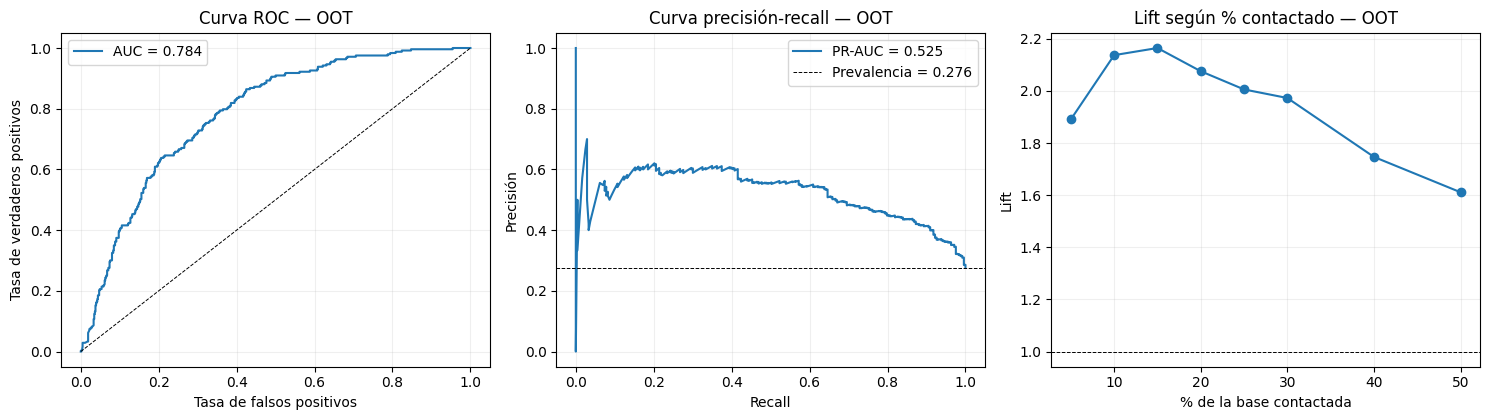

In [8]:
figura, ejes = plt.subplots(1, 3, figsize=(15, 4.3))

tasa_fp, tasa_vp, _ = roc_curve(objetivo_oot, probabilidades_oot)
ejes[0].plot(tasa_fp, tasa_vp, label=f"AUC = {auc_oot:.3f}")
ejes[0].plot([0, 1], [0, 1], "k--", lw=0.7)
ejes[0].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", title="Curva ROC — OOT")
ejes[0].legend()

precision, recall, _ = precision_recall_curve(objetivo_oot, probabilidades_oot)
ejes[1].plot(recall, precision, label=f"PR-AUC = {pr_auc_oot:.3f}")
ejes[1].axhline(prevalencia, color="k", ls="--", lw=0.7, label=f"Prevalencia = {prevalencia:.3f}")
ejes[1].set(xlabel="Recall", ylabel="Precisión", title="Curva precisión-recall — OOT")
ejes[1].legend()

ejes[2].plot(tabla_contacto["porcentaje_contactado"], tabla_contacto["lift"], marker="o")
ejes[2].axhline(1, color="k", ls="--", lw=0.7)
ejes[2].set(xlabel="% de la base contactada", ylabel="Lift", title="Lift según % contactado — OOT")

for eje in ejes:
    eje.grid(alpha=0.2)
figura.tight_layout()
figura.savefig("evaluacion_v2_oot.png", dpi=160)
plt.show()

## 7. Exportación y reporte

Guardamos las métricas en `oot_metricas_v2.json` y el reporte en `reports/evaluacion_v2.md`. Todos los números salen de esta ejecución.

In [9]:
def tabla_markdown(tabla):
    tabla = tabla.copy()
    for columna in tabla.select_dtypes(include="floating").columns:
        tabla[columna] = tabla[columna].map(lambda valor: "" if pd.isna(valor) else f"{valor:.4f}")
    filas = ["| " + " | ".join(map(str, tabla.columns)) + " |",
             "| " + " | ".join(["---"] * len(tabla.columns)) + " |"]
    filas += ["| " + " | ".join(map(str, fila)) + " |" for fila in tabla.itertuples(index=False)]
    return "\n".join(filas)


fecha = pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%d")
metricas = {
    "fecha_utc": fecha,
    "experimento": especificacion["experimento"],
    "modelo": configuracion["nombre"],
    "variables": variables,
    "ventana_meses": configuracion["ventana_meses"],
    "entrenamiento": {"desde": f"{entrenamiento['mes_obs'].min():%Y-%m}",
                      "hasta": f"{entrenamiento['mes_obs'].max():%Y-%m}", "filas": len(entrenamiento)},
    "versiones": {"evaluacion": versiones, "modelado": protocolo["versiones_librerias"]},
    "verificacion": verificacion,
    "oot": {
        "desde": f"{datos_oot['mes_obs'].min():%Y-%m}", "hasta": f"{datos_oot['mes_obs'].max():%Y-%m}",
        "filas": len(datos_oot), "vendedoras": len(filas_por_vendedora), "prevalencia": float(prevalencia),
        "metricas": tabla_oot.to_dict(orient="records"),
        "por_mes": tabla_meses.to_dict(orient="records"),
        "contacto": tabla_contacto.to_dict(orient="records"),
        "matrices": tabla_matrices.astype({"VP": int, "FP": int, "FN": int, "VN": int}).to_dict(orient="records"),
    },
}
Path("oot_metricas_v2.json").write_text(
    json.dumps(metricas, ensure_ascii=False, indent=2, default=float).replace("NaN", "null"), encoding="utf-8"
)

intervalo = tabla_oot.set_index("metrica")
reporte = "\n\n".join([
    "# Evaluación v2",
    f"Fecha UTC: {fecha}. Experimento de modelado: {especificacion['experimento']}. "
    f"Modelo: {configuracion['nombre']} ({len(variables)} variables: {', '.join(variables)}), "
    f"estrategia {configuracion['estrategia']}, ventana de {configuracion['ventana_meses']} meses.",
    f"Entrenamiento: {metricas['entrenamiento']['desde']} → {metricas['entrenamiento']['hasta']} "
    f"({len(entrenamiento):,} filas). Configuración fija desde la fase 04; reentrenada con xgboost "
    f"{versiones['xgboost']} (el modelado usó {protocolo['versiones_librerias']['xgboost']}).",
    "## Verificación con GroupKFold",
    tabla_markdown(tabla_verificacion),
    f"GroupKFold − StratifiedKFold: {diferencia:+.4f} de AUC. Mismo pool que el modelo final (ventana de "
    f"{configuracion['ventana_meses']} meses). Solo se interpreta la diferencia: los folds aleatorios mezclan "
    "épocas y entrenan con meses futuros.",
    "## Test OOT",
    f"{metricas['oot']['desde']} → {metricas['oot']['hasta']}: {len(datos_oot)} filas, "
    f"{len(filas_por_vendedora)} vendedoras, prevalencia {prevalencia:.4f}. "
    f"AUC {auc_oot:.4f} (IC 95 %: {intervalo.loc['AUC-ROC', 'ic95_inferior']:.4f}–"
    f"{intervalo.loc['AUC-ROC', 'ic95_superior']:.4f}), por bootstrap de vendedoras con 2.000 repeticiones.",
    tabla_markdown(tabla_oot),
    "### Por mes",
    tabla_markdown(tabla_meses),
    "### Según porcentaje contactado",
    tabla_markdown(tabla_contacto),
    "### Matriz de confusión",
    tabla_markdown(tabla_matrices),
    "Curvas: `05_evaluacion/evaluacion_v2_oot.png`.",
])
Path("../reports/evaluacion_v2.md").write_text(reporte + "\n", encoding="utf-8")
print("-> oot_metricas_v2.json, evaluacion_v2_oot.png, reports/evaluacion_v2.md")

-> oot_metricas_v2.json, evaluacion_v2_oot.png, reports/evaluacion_v2.md
